In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

# I. Cleaning the Data

### 1. Data granularity and exclusions

The original dataset contains 2,381 student records, with one row per student.

During data inspection, I identified two records associated with an Indian faculty member and the course Life Skills (Jeevan Kaushal) 2.0. These records were excluded because the course had a distinct set of quizzes that differed from those taken by the rest of the students. Since the analysis primarily focuses on Filipino learners, excluding these two records helps maintain a consistent analytical population and improves comparability across students.

The exclusion was based on differences in course and quiz structure, rather than nationality alone.

### 2. Sample selection and filtering

| Stage                                                                  | Remaining students | Excluded | % of original dataset |
| ---------------------------------------------------------------------- | ------------------ | -------- | --------------------- |
| Original dataset                                                       | 2,381              | -        | 100.00%               |
| Remove two records associated with Life Skills (Jeevan Kaushal) 2.0    | 2,379              | 2        | 99.92%                |
| Exclude students with fewer than two completed quizzes                 | 2,086              | 293      | 87.61%                |
| Restrict to courses with 14 quizzes, excluding courses with 11 quizzes | 2,048              | 38       | 86.01%                |
| Completed all 14 quizzes (none actually removed for this stage)        | 1,859              | 189      | 78.08%                |

The final analytical dataset contains 2,048 students who meet the inclusion criteria.

### 3. Selected variables and rationale

The selected variables support the analysis of students' quiz performance, course completion, and pacing relative to their enrollment and course end dates.

| Variable                            | Purpose                                                                                                                                                                                                                                              |
| ----------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `student_id`                        | Identifies each student and serves as the student-level identifier.                                                                                                                                                                                  |
| `batch_id`                          | Groups students by batch to enable cohort-level comparisons of quiz performance and completion pacing.                                                                                                                                               |
|`total_of_quizzes_incourse`.         | Number of Quizzes in the Course |
| `is_completed_all_courses`          | Indicates whether the student completed all assigned courses, providing context for interpreting their progress.                                                                                                                                     |
| `average_quiz_score`                | Serves as the primary source of truth for overall quiz performance. Although it is similar to the mean calculated from individual quiz scores, discrepancies exist, so the dataset-provided value is retained for consistency.                       |
| `lessons_average_score_in_course`   | Captures lesson-level performance, which is treated separately from quiz performance.                                                                                                                                                                |
| `total_lessons_completed_in_course` | Measures lesson completion and provides additional context on student engagement with course materials.                                                                                                                                              |
| `batch_end_date`                    | Serves as a proxy for the expected course end date and provides a reference point for assessing completion timing.                                                                                                                                   |
| `first_course_enrollment_date`      | Establishes the starting reference date for the student's course timeline. This was preferred over `batch_start_date` because quiz attempts can occur before the batch start date, whereas the enrollment date precedes the student's quiz attempts. |
| `last_quiz_attempt_date`            | Captures the date of the student's most recent quiz attempt and serves as the endpoint for calculating observed quiz activity.                                                                                                                       |

The `total_of_quizzes_incourse` and `batch_start_date` variables were not retained in the final selection. The former was unnecessary after restricting the analysis to courses with 14 quizzes, while the latter was less suitable than the student's first course enrollment date as the starting point for the timeline.

### 4. Important analytical considerations

- Quiz performance and lesson performance are distinct measures. They should not be treated as interchangeable indicators of learning.
- Completion status and pacing are also distinct. A student may complete quizzes quickly without necessarily completing all course requirements.
- The last quiz attempt is not necessarily the course completion date. It is an observable proxy for the end of quiz activity, not definitive evidence that the student finished the course on that date.
- The 14-quiz restriction improves comparability. Students taking courses with different quiz requirements may not be directly comparable in terms of quiz completion or pacing.

These criteria establish a consistent population for the subsequent analysis of quiz-taking behavior and potential early completion risk. However, unusually fast quiz completion should be interpreted as a potential risk indicator, not proof that a student failed to learn the material.

In [38]:
student_data_df = pd.read_excel('Case Assignment - Sr Associate - Philippines - data.xlsx')
student_data_df.rename(columns={'competency_quiz_score_1': 'Competency_quiz_score_1'}, inplace=True)

# get competency quiz columns 
competency_name_lists = [f"Competency_name_{i}" for i in range(1, 15)]
competency_quiz_submit_lists = [f"Competency_quiz_submit_{i}" for i in range(1, 15)]
competency_quiz_score_lists = [f"Competency_quiz_score_{i}" for i in range(1, 15)]
competency_quizzes = competency_name_lists + competency_quiz_submit_lists + competency_quiz_score_lists

# remove the two students that have a different course
student_data_df = student_data_df[student_data_df['course_name'] != 'Life Skills (Jeevan Kaushal) 2.0'].copy()
# remove students that dont have at least two answered quizzes
student_data_df = student_data_df.dropna(subset=competency_quiz_submit_lists, thresh=2)

In [39]:
competency_scores = []

for _, student_row in student_data_df.iterrows():
    if student_row['total_of_quizzes_incourse'] not in [11, 14]:
        continue

    student_id = student_row['student_id']

    for competency_number, (competency_name_col, competency_score_col) in enumerate(
        zip(competency_name_lists, competency_quiz_score_lists),
        start=1
    ):
        competency_name = student_row[competency_name_col]
        competency_score = student_row[competency_score_col]

        if pd.isna(competency_name) and pd.isna(competency_score):
            continue

        competency_scores.append({
            'student_id': student_id,
            'competency_number': competency_number,
            'competency_name': competency_name,
            'competency_score': competency_score,
        })

fact_competency_score_df = pd.DataFrame(competency_scores)

In [40]:
competency_quiz_time_deltas = {f'Competency_quiz_delta_{i}':[] for i in range(1, 15)}
competency_quiz_time_submits = {i:[] for i in competency_quiz_submit_lists}
competency_quiz_time_score = {i:[] for i in competency_quiz_score_lists}

competency_quizzes = {
    **competency_quiz_time_deltas,
    **competency_quiz_time_submits, 
    **competency_quiz_time_score
}

In [41]:
num_missing_quizzes = (
    student_data_df[competency_quiz_submit_lists]
    .isnull()
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

num_missing_quizzes

0     1859
1       63
2       13
3       23
4       16
5       10
6       11
7       15
8       14
9        8
10      13
11      22
12      19
Name: count, dtype: int64

In [42]:
competency_quizzes = []

for _, student_row in student_data_df.iterrows():
    student_quizzes = {
        'student_id': student_row['student_id'],
        'total_of_quizzes_incourse': student_row['total_of_quizzes_incourse'],
        'is_completed_all_courses': student_row['is_completed_all_courses'],
        'number_of_quiztaken': student_row['number_of_quiztaken'],
        'average_quiz_score': student_row['average_quiz_score'],
        'lessons_average_score_in_course': (
            student_row['lessons_average_score_in_course']
        ),
        'first_course_enrollment_date': (
            student_row['first_course_enrollment_date']
        ),
    }

    previous_date = student_row['first_course_enrollment_date']

    completion_days = [
        int((completion_date - previous_date).days)
        for completion_date 
        in student_row[competency_quiz_submit_lists].dropna().sort_values()
    ]

    for i, day in enumerate(completion_days, start=1):
        student_quizzes[f'num_days_to_complete_{i}_quizzes'] = day

    competency_quizzes.append(student_quizzes)

competency_quizzes_df = pd.DataFrame(competency_quizzes)

# competency_quizzes_df.to_csv(
#     'cleaned_case_assignment.csv',
#     index=False
# )

In [43]:
competency_quizzes_df['total_of_quizzes_incourse'].value_counts()

total_of_quizzes_incourse
14    2048
11      38
Name: count, dtype: int64

In [44]:
student_data_df['batch_duration'].value_counts()

batch_duration
2.5    2040
3.0      46
Name: count, dtype: int64

In [45]:
(student_data_df['course_duration_hours'] / student_data_df['hours_week']).describe()

count    2086.000000
mean        3.854858
std         0.662447
min         2.323529
25%         3.766667
50%         3.766667
75%         3.766667
max         8.777778
dtype: float64

In [46]:
(student_data_df['first_course_enrollment_date'] - student_data_df['batch_start_date']).dt.days.describe()

count    2086.000000
mean        2.240173
std         3.816704
min        -2.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        22.000000
dtype: float64

In [47]:
competency_quizzes_df['num_days_to_complete_14_quizzes'].quantile(0.10)

np.float64(11.0)

# II. Exploratory Data Analysis

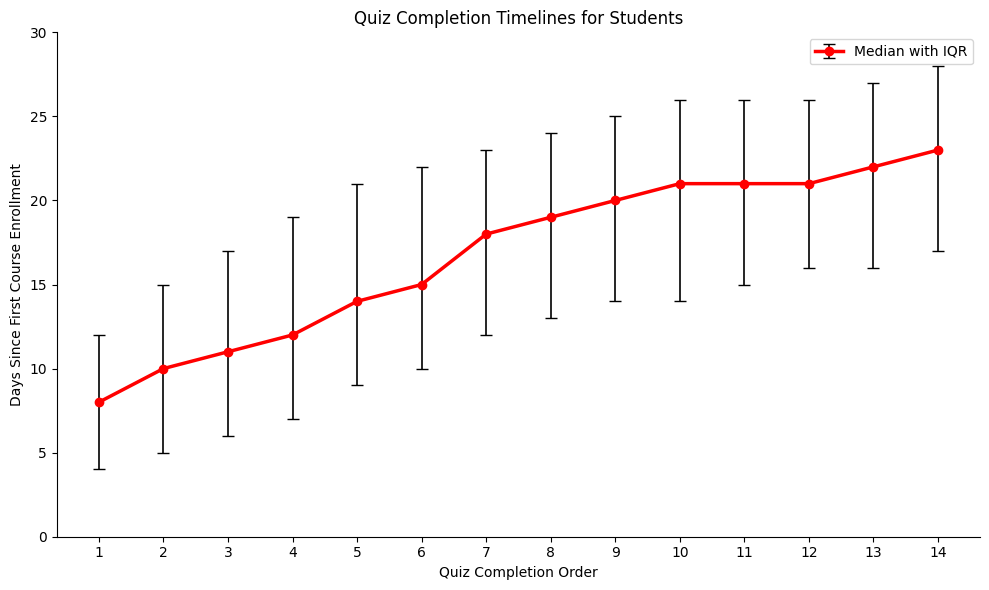

In [77]:
# Filter students who have 14 quizzes in the course and completed all courses.
students_14_quizzes = competency_quizzes_df[
    (competency_quizzes_df['total_of_quizzes_incourse'] == 14) &
    (competency_quizzes_df['is_completed_all_courses'] == 'Y')
]

quiz_day_cols = [
    f'num_days_to_complete_{i}_quizzes'
    for i in range(1, 15)
]

plt.figure(figsize=(10, 6))

all_quiz_days = students_14_quizzes[quiz_day_cols].to_numpy(dtype=float)

# Calculate median and interquartile range for each quiz milestone.
median_quiz_days = np.nanmedian(all_quiz_days, axis=0)
q25 = np.nanpercentile(all_quiz_days, 25, axis=0)
q75 = np.nanpercentile(all_quiz_days, 75, axis=0)

# Asymmetric error bars: median down to Q1, median up to Q3.
yerr = np.array([
    median_quiz_days - q25,
    q75 - median_quiz_days
])

plt.errorbar(
    range(1, 15),
    median_quiz_days,
    yerr=yerr,
    color='red',
    ecolor='black',
    elinewidth=1.2,
    capsize=4,
    linewidth=2.5,
    marker='o',
    label='Median with IQR'
)

plt.xlabel('Quiz Completion Order')
plt.ylabel('Days Since First Course Enrollment')
plt.ylim(0, 30)
plt.title('Quiz Completion Timelines for Students')
plt.xticks(range(1, 15))
plt.gca().spines[['top', 'right']].set_visible(False)
plt.legend()
plt.tight_layout()
plt.show()

# III. Construct the seven tables

## a. Get the Columns

In [49]:
institution_cols = [
    'institute_id',
    'institute_name',
    'institute_curriculum_type',
    'region_name',
    'country_name',
    'city_name',
]

faculty_cols = [
    'faculty_id', #PK
    'institute_id', # FK
    # 'faculty_email',
    # 'faculty_first_name',
    # 'faculty_last_name',
    'faculty_country_name',
    'faculty_state_name',
    'faculty_city_name',
    'faculty_district_name',
]

batch_cols = [
    'batch_id',
    'faculty_id', # FK
    'course_id', # FK
    'batch_name',
    'batch_duration',
    'batch_classification',
    'batch_created_date',
    'batch_start_date',
    'batch_end_date',
    'batch_updatedate',
    'batch_status',
    'total_number_student_enrolled',
]

course_cols = [
    'course_id',
    'course_name',
    'course_duration_hours',
    'hours_week',
    'total_lessons_in_course',
    'total_of_quizzes_incourse',
]

student_cols = [
    'student_id',
    'batch_id',
    'lmsuserid',
    # 'user_email',
    # 'user_first_name',
    # 'user_last_name',
    'user_country_name',
    'user_state_name',
    'user_city_name',
    'user_district_name',
    'user_registartion_date',
    'real_degree',
    'real_institutename',
    'actual_graduationdate',
    'student_status_inbatch',
    'batch_joined_date',
    'first_course_enrollment_date',
    # 'first_placement_date', # this is just all blanks
    # 'expected_placement_eligible_date',
    'is_completed_all_courses',
    'is_transformed_in_all_courses',
    # 'is_eligible_for_placement', # they're all zero anyways
    'Pos_Last_visited_status',
    'student_journey',
]

competency_quizzes = competency_quizzes_df.drop(
    columns=['total_of_quizzes_incourse', 'is_completed_all_courses', 'first_course_enrollment_date']
)

employment_cols = [
    'student_id', # FK
    'employmentsector',
    'employername',
    'employment_startdate',
    #'placement_reporting_date',
    #'salary_at_placement_usd',
    #'first_placement_date',
]

# Validate keys build the dimension tables

In [50]:
def select_available_columns(df, columns):
    """Select the requested columns that exist in the source DataFrame."""
    return df[[col for col in columns if col in df.columns]].copy()

In [51]:
def make_dimension(df, columns, key):
    """Build a dimension after validating its key and attributes."""
    result = select_available_columns(df, columns)

    if key not in result.columns:
        raise ValueError(f'Missing required key column: {key}')

    if result[key].isna().any():
        raise ValueError(f'{key} contains null values.')

    attributes = [
        col for col in result.columns
        if col != key
    ]

    if attributes:
        conflicts = (
            result.groupby(key, dropna=False)[attributes]
            .nunique(dropna=False)
            .gt(1)
            .any(axis=1)
        )

        if conflicts.any(): # this is to print if actually we chose our PK badly
            bad_ids = conflicts[conflicts].index.tolist()[:10]
            raise ValueError(
                f'{key} has conflicting attribute values. '
                f'Example IDs: {bad_ids}'
            )

    return result.drop_duplicates(subset=key).reset_index(drop=True)


dim_institution = make_dimension(
    student_data_df, institution_cols, 'institute_id'
)

dim_faculty = make_dimension(
    student_data_df, faculty_cols, 'faculty_id'
)

dim_batch = make_dimension(
    student_data_df, batch_cols, 'batch_id'
)

dim_course = make_dimension(
    student_data_df, course_cols, 'course_id'
)

dim_student = make_dimension(
    student_data_df, student_cols, 'student_id'
)

In [52]:
student_data_df[student_data_df['faculty_id'] == '8f20d6bf-db4e-4650-9e23-a1aeb9218786'][faculty_cols]

,faculty_id,institute_id,faculty_country_name,faculty_state_name,faculty_city_name,faculty_district_name


# Validate Foreign Keys

In [53]:
def validate_foreign_key(
    child_df,
    child_key,
    parent_df,
    parent_key,
):
    """Check that non-null child keys exist in the parent table."""
    if child_key not in child_df.columns:
        return

    if parent_key not in parent_df.columns:
        raise ValueError(f'Missing parent key: {parent_key}')

    child_values = set(child_df[child_key].dropna())
    parent_values = set(parent_df[parent_key].dropna())

    missing = child_values - parent_values

    if missing:
        raise ValueError(
            f'{child_key} contains keys absent from {parent_key}: '
            f'{list(missing)[:10]}'
        )


validate_foreign_key(
    dim_faculty, 'institute_id',
    dim_institution, 'institute_id',
)

validate_foreign_key(
    dim_batch, 'faculty_id',
    dim_faculty, 'faculty_id',
)

validate_foreign_key(
    dim_batch, 'course_id',
    dim_course, 'course_id',
)

validate_foreign_key(
    dim_student, 'batch_id',
    dim_batch, 'batch_id',
)

In [54]:
fact_employment = select_available_columns(
    student_data_df,
    employment_cols,
)

# Keep records with at least one populated employment attribute.
employment_attributes = [
    col for col in fact_employment.columns
    if col != 'student_id'
]

# create a filter if a student has any employment data
has_employment_data = fact_employment[
    employment_attributes
].notna().any(axis=1)

fact_employment = fact_employment[
    has_employment_data
].copy()

fact_employment['employment_startdate'] = pd.to_datetime(fact_employment['employment_startdate'].str[:10])

In [55]:
quiz_completion_cols = [
    f'num_days_to_complete_{i}_quizzes'
    for i in range(1, 15)
]

quiz_completion_timeline = competency_quizzes_df.melt(
    id_vars=['student_id'],
    value_vars=quiz_completion_cols,
    var_name='completion_milestone',
    value_name='num_days_to_complete_quizzes',
)

quiz_completion_timeline['quizzes_completed'] = (
    quiz_completion_timeline['completion_milestone']
    .str.extract(r'num_days_to_complete_(\d+)_quizzes')
    .astype(int)
)

quiz_completion_timeline = quiz_completion_timeline.dropna(
    subset=['num_days_to_complete_quizzes']
)

quiz_completion_timeline = quiz_completion_timeline[
    [
        'student_id',
        'quizzes_completed',
        'num_days_to_complete_quizzes',
    ]
]

tables = {
    'DimInstitution': dim_institution,
    'DimFaculty': dim_faculty,
    'DimCourse': dim_course,
    'DimBatch': dim_batch,
    'DimStudent': dim_student,
    'FactCompetencyQuiz': competency_quizzes,
    'FactCompetencyQuizScore': fact_competency_score_df,
    'FactEmployment': fact_employment,
    'FactQuizCompletionTimeline': quiz_completion_timeline
}

In [56]:
set(quiz_completion_timeline['student_id']) - set(student_data_df['student_id'])

set()

In [57]:
output_path = Path('learning_analytics.xlsx')

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    for table_name, df in tables.items():
        export_df = df.copy()

        for column in export_df.select_dtypes(
            include=['timedelta64[ns]']
        ).columns:
            export_df[column] = (
                export_df[column].dt.total_seconds()
            )

        export_df.to_excel(
            writer,
            sheet_name=table_name,
            index=False,
        )

print(f'Exported to: {output_path.resolve()}')

Exported to: /Users/jfv/Desktop/wadhwani/11_Case_Study/learning_analytics.xlsx


# this is for me na

In [58]:
df = competency_quizzes.copy()

# Ensure the columns are numeric
numeric_cols = [
    'number_of_quiztaken',
    'num_days_to_complete_7_quizzes',
    'num_days_to_complete_14_quizzes'
]

df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors='coerce'
)

# Apply the Early vs. Normal classification
is_early = (
    (df['number_of_quiztaken'] >= 7)
    & (
        (
            df['num_days_to_complete_7_quizzes'].notna()
        )
        | (
            df['num_days_to_complete_14_quizzes'].notna()
        )
    )
    & (
        (
            df['num_days_to_complete_7_quizzes'].notna()
            & (df['num_days_to_complete_7_quizzes'] <= 2)
        )
        | (
            df['num_days_to_complete_14_quizzes'].notna()
            & (df['num_days_to_complete_14_quizzes'] <= 3)
        )
    )
)

df['Is_Too_Early'] = np.where(
    is_early,
    'Early',
    'Normal'
)

In [59]:
from scipy.stats import chi2_contingency

helper_df = df.merge(student_data_df, on='student_id')
contingency_table = pd.crosstab(
    helper_df['is_transformed_in_all_courses'],
    helper_df['Is_Too_Early']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Contingency table:")
print(contingency_table)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Evidence of an association between the variables.")
else:
    print("Insufficient evidence of an association.")

Contingency table:
Is_Too_Early                   Early  Normal
is_transformed_in_all_courses               
N                                 12     253
Y                                 73    1748

Chi-square statistic: 0.0545
Degrees of freedom: 1
P-value: 0.8155
Insufficient evidence of an association.


In [78]:
import numpy as np
import pandas as pd
from scipy import stats


def compare_early_testers(
    df,
    completion_column,
    percentiles=range(1, 10),
):
    results = []

    # outcome = 'lessons_average_score_in_course'
    outcome = 'average_quiz_score'

    for percentile in percentiles:
        threshold = df[completion_column].quantile(
            percentile / 100
        )

        early_testers = df.loc[
            df[completion_column] <= threshold
        ]
        other_students = df.loc[
            df[completion_column] > threshold
        ]

        early = early_testers[outcome].dropna()
        others = other_students[outcome].dropna()

        if len(early) < 2 or len(others) < 2:
            continue

        _, p_value = stats.ttest_ind(
            early,
            others,
            equal_var=False,
        )

        pooled_sd = np.sqrt(
            (
                (len(early) - 1) * early.var(ddof=1)
                + (len(others) - 1) * others.var(ddof=1)
            ) / (len(early) + len(others) - 2)
        )

        cohens_d = (
            (early.mean() - others.mean()) / pooled_sd
            if pooled_sd > 0
            else np.nan
        )

        results.append({
            'early_tester_definition': completion_column,
            'percentile': percentile,
            'completion_days_cutoff': threshold,
            'n_early_testers': len(early),
            'n_other_students': len(others),
            'early_mean_lesson_score': early.mean(),
            'other_mean_lesson_score': others.mean(),
            'mean_difference': early.mean() - others.mean(),
            'cohens_d': cohens_d,
            'p_value': p_value,
        })

    return pd.DataFrame(results)


results = pd.concat(
    [
        compare_early_testers(
            competency_quizzes,
            'num_days_to_complete_7_quizzes',
        ),
        compare_early_testers(
            competency_quizzes,
            'num_days_to_complete_14_quizzes',
        ),
    ],
    ignore_index=True,
)

results.round(4).sort_values(
    by=['early_tester_definition', 'percentile']
)

,early_tester_definition,percentile,completion_days_cutoff,n_early_testers,n_other_students,early_mean_lesson_score,other_mean_lesson_score,mean_difference,cohens_d,p_value
9,num_days_to_complete_14_quizzes,1,1.00,29,1830,92.1379,90.1388,1.9991,0.2322,0.0908
10,num_days_to_complete_14_quizzes,2,3.00,48,1811,91.8333,90.1259,1.7074,0.1984,0.0945
11,num_days_to_complete_14_quizzes,3,4.00,61,1798,92.1475,90.1029,2.0446,0.2376,0.0229
12,num_days_to_complete_14_quizzes,4,5.32,75,1784,91.8533,90.0992,1.7541,0.2039,0.0270
13,num_days_to_complete_14_quizzes,5,7.00,99,1760,91.5859,90.0903,1.4955,0.1738,0.0646
14,num_days_to_complete_14_quizzes,6,9.00,130,1729,92.4000,90.0023,2.3977,0.2791,0.0005
15,num_days_to_complete_14_quizzes,7,10.00,165,1694,92.5879,89.9345,2.6534,0.3093,0.0000
16,num_days_to_complete_14_quizzes,8,10.00,165,1694,92.5879,89.9345,2.6534,0.3093,0.0000
17,num_days_to_complete_14_quizzes,9,11.00,195,1664,92.4923,89.8978,2.5945,0.3026,0.0000
0,num_days_to_complete_7_quizzes,1,0.00,27,1983,87.7407,87.2123,0.5284,0.0367,0.8497
